# 🇳🇬 Nigerian Macroeconomic Analysis: What Drives Inflation? (2008–2024)

* **Author:** Michael Uche Wisdom (Uche)
* **Tools Used:** Python, Pandas, Matplotlib, Jupyter Notebook
* **Project Objective:** Analyze historical Nigerian macroeconomic data to uncover the true drivers behind inflation trends, moving past yearly averages to explore correlations and extreme economic swings.

---
### 📌 Executive Summary & Key Findings:
* **Food CPI vs. Inflation:** Discovered a strong positive correlation ($0.896$), proving that domestic food prices are heavily tied to headline inflation.
* **Crude Oil vs. Inflation:** Found a negligible correlation ($-0.055$), showing that global oil prices have less direct impact on domestic inflation than expected.
* **The Extremes:** Utilizing min/max aggregation revealed that smooth yearly averages often mask severe intra-year price spikes (such as inflation peaking past $18.5\%$ in 2016).m

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
print ("day 16: Ready to analyze")

day 16: Ready to analyze


In [2]:
df=pd.read_excel('NigeriaInflationRates.csv.xlsx')
df.head()

C:\Users\Uche Wisdom Michael\AppData\Roaming\Python\Python314\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Slicer List extension is not supported and will be removed
  warn(msg)


,Year,Month,Inflation_Rate,Crude Oil Price,Production,Crude Oil Export,CPI_Food,CPI_Energy,CPI_Health,CPI_Transport,CPI_Communication,CPI_Education,Unnamed: 12,Unnamed: 13,Unnamed: 14
0,2008,1,8.6,94.26,2.17,1.72,75.534431,84.612846,83.863139,86.530038,83.129440,75.284466,NaN,NaN,NaN
1,2008,2,8.0,98.15,2.08,1.63,75.154185,85.231632,83.365891,88.355236,82.889814,75.457619,NaN,NaN,NaN
2,2008,3,7.8,103.73,2.06,1.61,78.242523,83.251516,86.082993,84.376304,81.893471,74.826847,Row Labels,Average of Inflation_Rate,Average of Crude Oil Price
3,2008,4,8.2,116.73,1.96,1.51,79.434268,84.348830,89.445332,88.600334,93.937865,73.664248,2008,8.2,116.73
4,2008,5,9.7,126.57,2.05,1.60,80.783677,85.574027,90.540461,87.932833,97.553285,74.880442,2009,13.3,51.16


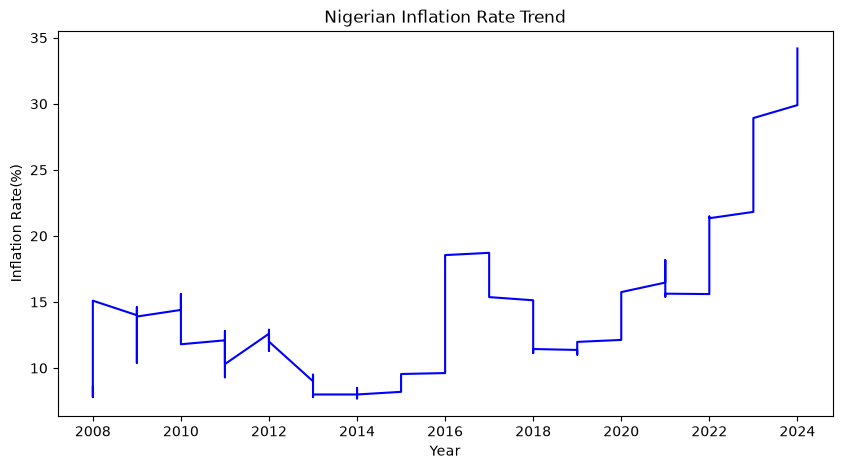

In [3]:
plt.figure(figsize=(10, 5))
plt.plot(df['Year'],
df['Inflation_Rate'],color='blue')
plt.title('Nigerian Inflation Rate Trend')
plt.ylabel('Inflation Rate(%)')
plt.xlabel('Year')
plt.show()

In [4]:
df.columns.tolist()

['Year',
 'Month',
 'Inflation_Rate',
 'Crude Oil Price',
 'Production',
 'Crude Oil Export',
 'CPI_Food',
 'CPI_Energy',
 'CPI_Health',
 'CPI_Transport',
 'CPI_Communication',
 'CPI_Education',
 'Unnamed: 12',
 'Unnamed: 13',
 'Unnamed: 14']

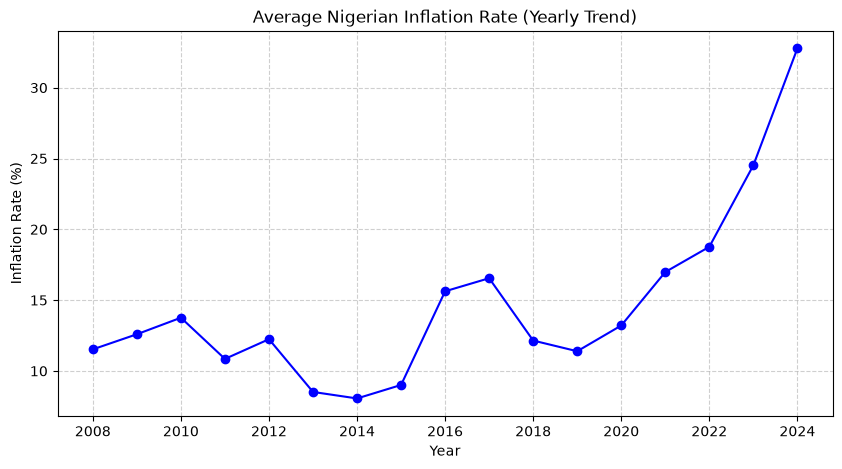

In [5]:
# Group the data by Year and calculate the average inflation rate for each year
yearly_df = df.groupby('Year')['Inflation_Rate'].mean().reset_index()

# Plot the smoothed yearly average
plt.figure(figsize=(10, 5))
plt.plot(yearly_df['Year'], yearly_df['Inflation_Rate'], color='blue', marker='o')
plt.title('Average Nigerian Inflation Rate (Yearly Trend)')
plt.ylabel('Inflation Rate (%)')
plt.xlabel('Year')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [6]:
# Print all column names in your existing dataframe
print(df.columns)

Index(['Year', 'Month', 'Inflation_Rate', 'Crude Oil Price', 'Production',
       'Crude Oil Export', 'CPI_Food', 'CPI_Energy', 'CPI_Health',
       'CPI_Transport', 'CPI_Communication', 'CPI_Education', 'Unnamed: 12',
       'Unnamed: 13', 'Unnamed: 14'],
      dtype='str')


In [7]:
# Group by Year and calculate the average for Crude Oil Price as well
yearly_oil_df = df.groupby('Year')['Crude Oil Price'].mean().reset_index()

# Quick peek to make sure it calculated correctly
yearly_oil_df.head()

,Year,Crude Oil Price
0,2008,101.022500
1,2009,63.900000
2,2010,80.899167
3,2011,113.760000
4,2012,113.720000


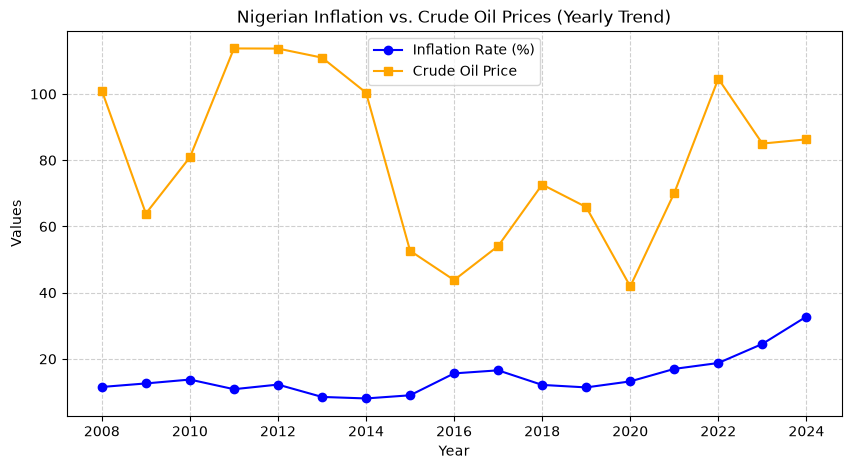

In [8]:
# Create a multi-line chart comparing Inflation and Crude Oil Prices
plt.figure(figsize=(10, 5))

# Plot Inflation Rate (using a blue line)
plt.plot(yearly_df['Year'], yearly_df['Inflation_Rate'], color='blue', marker='o', label='Inflation Rate (%)')

# Plot Crude Oil Price (using an orange line)
plt.plot(yearly_oil_df['Year'], yearly_oil_df['Crude Oil Price'], color='orange', marker='s', label='Crude Oil Price')

# Add titles, labels, and legend
plt.title('Nigerian Inflation vs. Crude Oil Prices (Yearly Trend)')
plt.xlabel('Year')
plt.ylabel('Values')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### 1. Statistical Correlation Analysis
Testing the statistical relationships between inflation and potential macroeconomic drivers.

In [9]:
# Calculate the statistical correlation between Inflation Rate and Crude Oil Price
correlation = yearly_df['Inflation_Rate'].corr(yearly_oil_df['Crude Oil Price'])

print(f"Correlation Coefficient: {correlation}")

Correlation Coefficient: -0.055886921153693814


In [10]:
# Group by Year for another column (e.g., Food CPI or Energy CPI)
yearly_other_df = df.groupby('Year')['CPI_Food'].mean().reset_index()

# Calculate correlation with Inflation Rate
other_correlation = yearly_df['Inflation_Rate'].corr(yearly_other_df['CPI_Food'])

print(f"CPI Food Correlation Coefficient: {other_correlation}")

CPI Food Correlation Coefficient: 0.8961504557181165


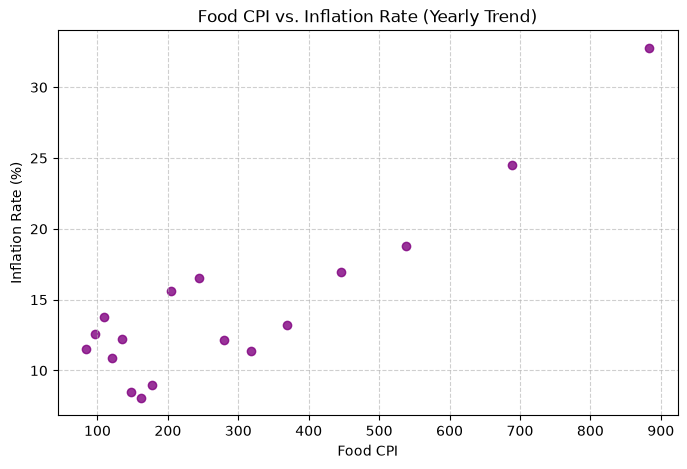

In [12]:
import matplotlib.pyplot as plt

# Set up a clean scatter plot using matplotlib
plt.figure(figsize=(8, 5))
plt.scatter(yearly_other_df['CPI_Food'], yearly_df['Inflation_Rate'], color='purple', alpha=0.8)

# Add styling, labels, and grid
plt.title('Food CPI vs. Inflation Rate (Yearly Trend)')
plt.xlabel('Food CPI')
plt.ylabel('Inflation Rate (%)')
plt.grid(True, linestyle='--', alpha=0.6)

# Display the plot
plt.show()

### 2. Yearly Aggregate Summary (Min, Max, Mean)
Grouping data by year to extract hidden extremes rather than relying solely on smooth averages.

In [13]:
# Create a comprehensive yearly summary table for Inflation and Food CPI
summary_df = df.groupby('Year').agg({
    'Inflation_Rate': ['mean', 'max'],
    'CPI_Food': ['mean', 'min']
}).reset_index()

# Display the top rows of your summary table
print(summary_df.head(10))

   Year Inflation_Rate           CPI_Food            
                  mean    max        mean         min
0  2008      11.525000  15.10   83.442306   75.154185
1  2009      12.591667  14.60   95.825573   89.459773
2  2010      13.758333  15.60  109.933956  103.700296
3  2011      10.850000  12.80  121.254742  114.334805
4  2012      12.241667  12.90  134.951907  129.096828
5  2013       8.516667   9.50  148.035516  142.320790
6  2014       8.058333   8.50  162.071004  155.515546
7  2015       9.010000   9.55  178.112758  169.845780
8  2016      15.625000  18.55  204.733925  187.920692
9  2017      16.547500  18.72  244.751544  221.404852


### 3. Macroeconomic Visualization Dashboard
Combining multi-panel trends into a cohesive visual report for stakeholders.

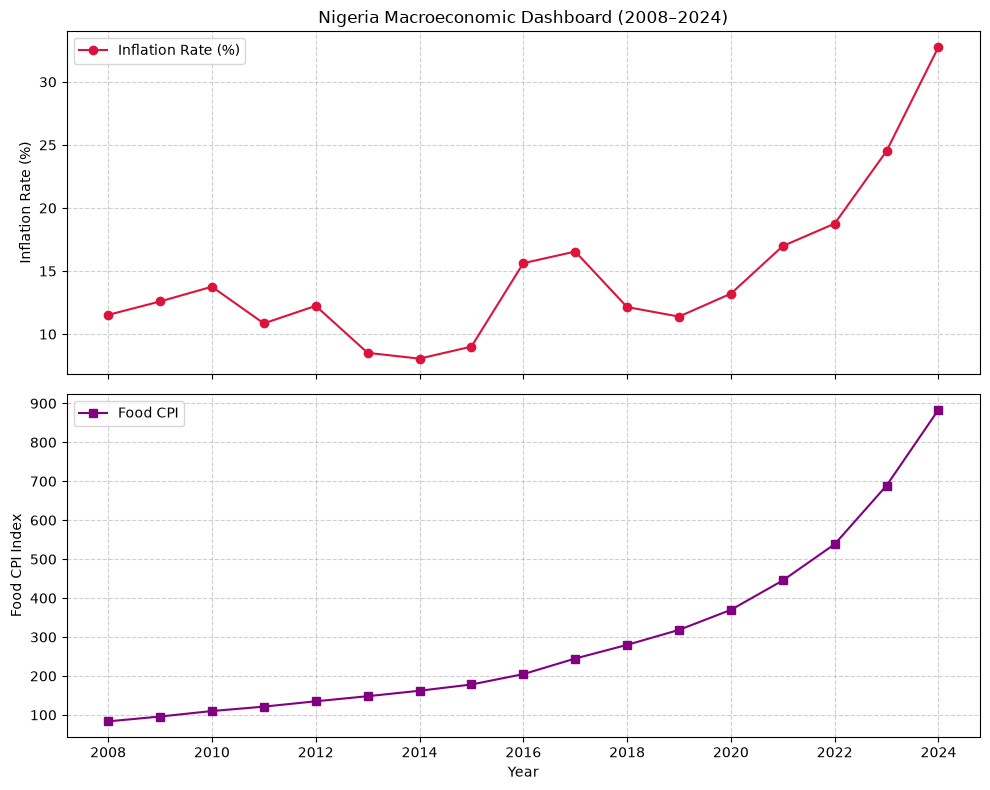

In [14]:
import matplotlib.pyplot as plt

# Set up a figure with 2 subplots stacked vertically
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Top Plot: Inflation Rate vs Crude Oil Price over the years
ax1.plot(yearly_df['Year'], yearly_df['Inflation_Rate'], color='crimson', marker='o', label='Inflation Rate (%)')
ax1.set_title('Nigeria Macroeconomic Dashboard (2008–2024)')
ax1.set_ylabel('Inflation Rate (%)')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper left')

# Bottom Plot: Food CPI trend
ax2.plot(yearly_other_df['Year'], yearly_other_df['CPI_Food'], color='purple', marker='s', label='Food CPI')
ax2.set_xlabel('Year')
ax2.set_ylabel('Food CPI Index')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='upper left')

# Adjust layout for neatness
plt.tight_layout()
plt.show()